In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [15]:
X = 6*np.random.rand(300,1) - 3
y = 0.8*X**2 + 0.5*X + 9 + np.random.randn(300,1)

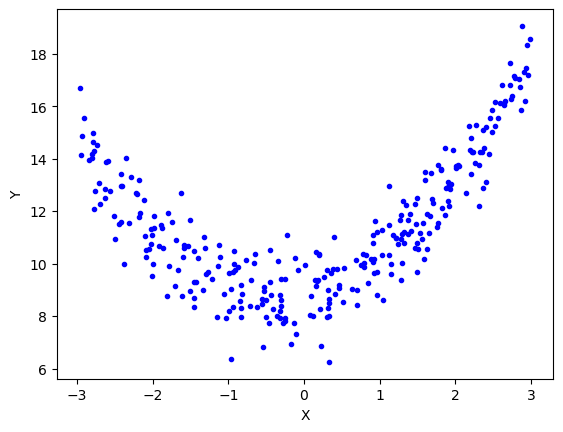

In [16]:
plt.plot(X,y,'b.')
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [17]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [18]:
lr = LinearRegression()

In [19]:
lr.fit(X_train,y_train)

LinearRegression()

In [20]:
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.21704169424784558

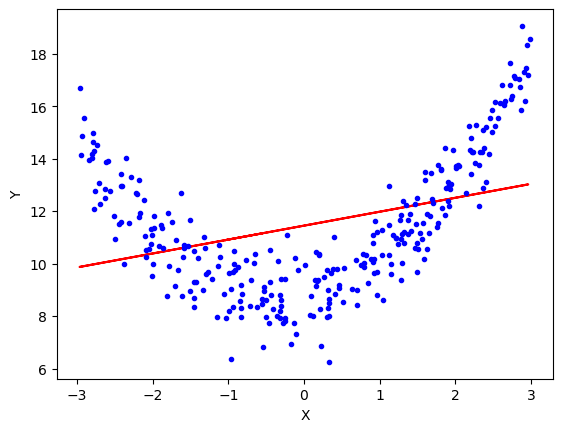

In [21]:
plt.plot(X_train,lr.predict(X_train),color = 'r')
plt.plot(X,y,'b.')
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [22]:
# degree 2
poly = PolynomialFeatures(degree=2,include_bias=True)

X_train_trans = poly.fit_transform(X_train)
X_test_trans = poly.transform(X_test)

In [23]:
print(X_train[0])
print(X_train_trans[0])

[-0.55935498]
[ 1.         -0.55935498  0.31287799]


In [24]:
lr = LinearRegression()
lr.fit(X_train_trans,y_train)

LinearRegression()

In [25]:
y_pred = lr.predict(X_test_trans)

In [26]:
r2_score(y_test,y_pred)

0.8411954791892461

In [27]:
print(lr.coef_)
print(lr.intercept_)

[[0.         0.53580791 0.84662505]]
[8.83477223]


In [28]:
X_new=np.linspace(-3, 3, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)
y_new = lr.predict(X_new_poly)

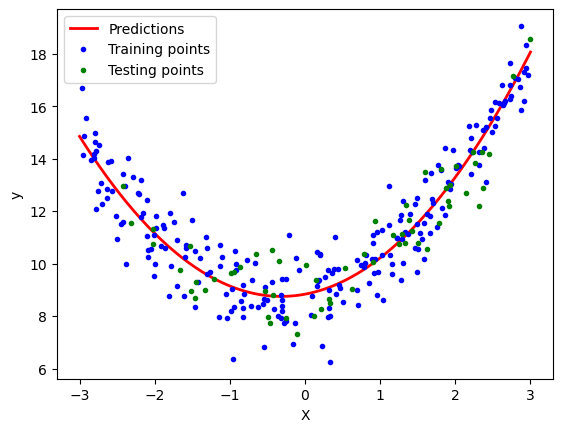

In [30]:
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.plot(X_train, y_train, "b.",label='Training points')
plt.plot(X_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()